# HE4045 Group 10: Stock buybacks and later returns (code appendix)
Goh Yee Xi, Ong Zheng Yang James, Tan Jin Yenn, Tay Jian Yuan

This notebook is the reproducible appendix to our report. It rebuilds every number, table and figure in the report from the raw WRDS data. Each section says which part of the report it matches, and each output is labelled with the report's figure or table number.

**Dependencies**

| Package | Version tested | Used for |
|---|---|---|
| Python | 3.13 | |
| pandas | 2.2 or 2.3 | data handling |
| numpy | 2.1 to 2.3 | calculations |
| matplotlib | 3.10 | figures |
| statsmodels | 0.15 | adding the constant term in the regressions |
| linearmodels | **7.1** | panel regressions with fixed effects and clustered standard errors |
| pyarrow | 21 | reading and writing the parquet data files |
| wrds | any recent | downloading the data (Section 1 only) |
| python-dotenv | any recent | reading the WRDS login from `.env` (Section 1 only) |

Use linearmodels 7.1: with 7.0, a few industry p-values behind Figure 10 change in the third decimal. To install:
```
pip install "pandas>=2.2" "numpy>=2.1" "matplotlib>=3.10" "statsmodels>=0.15" "linearmodels==7.1" "pyarrow>=21"
pip install wrds python-dotenv    # only needed to download the data
```
You also need a WRDS account with access to Compustat, CRSP and the Fama-French factors.

**How to run**
1. **Get the data (once).** Put your WRDS login in a file named `.env` next to this notebook (`WRDS_USERNAME=...` and `WRDS_PASSWORD=...`), set `DOWNLOAD_DATA = True` in the setup cell, and run the notebook. The five WRDS tables are saved as parquet files in `data/` (Section 1).
2. **Run everything.** Kernel > Restart & Run All. Run the notebook from its own folder, because the paths are relative. It takes about one to two minutes on a laptop.

**Contents**
0. Setup
1. Download the data from WRDS
2. Load the raw tables (report Tables 2–6)
3. Clean and merge (report Section 3.3, Figures 1–6)
4. The final panel (report Section 3.4, Table 8)
5. Descriptive evidence (report Section 4, Figures 7–9)
6. Regressions (report Sections 5–6, Tables 9–11, Figure 10)
7. The WRDS queries in full

## 0. Setup
Packages, plot style and small helper functions. Set `DOWNLOAD_DATA = True` the first time, to download the data from WRDS (Section 1).

In [1]:
import textwrap
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from linearmodels.panel import PanelOLS

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
NAVY, ORANGE, GREY = "#1f4e79", "#d9822b", "#999999"

DATA = Path("data")
DOWNLOAD_DATA = False    # True = download the five WRDS tables into data/ first (needs a WRDS login in .env)


def to_float(df):
    """Parquet keeps pandas' nullable number types (Float64, Int64); plain floats are easier to work with."""
    df = df.copy()
    for c in df.columns:
        if str(df[c].dtype) in ("Float64", "Int64", "Int32", "Int16", "boolean"):
            df[c] = df[c].astype("float64")
    return df


def winsorize(s, lower=0.01, upper=0.99):
    """Cap extreme values at the given percentiles (keeps the observation, limits its influence)."""
    lo, hi = s.quantile([lower, upper])
    return s.clip(lo, hi)


sample_log = []


def log_step(step, df):
    sample_log.append({"step": step, "firm-quarters": len(df), "firms": df["gvkey"].nunique()})

## 1. Download the data from WRDS
We use five WRDS tables, all for 2008–2025 (2008–2009 are used only to build lagged variables):

| Saved as | WRDS table | Used for |
|---|---|---|
| `data/comp_fundq.parquet` | `comp.fundq` (with `comp.company` for the SIC code) | buybacks, accounts, industry code |
| `data/comp_filedates.parquet` | `comp.co_filedate` | 10-Q / 10-K filing dates |
| `data/crsp_msf.parquet` | `crsp.msf_v2` | monthly stock returns, market value |
| `data/ccm_link.parquet` | `crsp.ccmxpf_linktable` | link from Compustat `gvkey` to CRSP `permno` |
| `data/ff_monthly.parquet` | `ff.fivefactors_monthly` | monthly market return |

The cell below holds the exact SQL and downloads the tables only if `DOWNLOAD_DATA = True`. Compustat quarterly and CRSP monthly are downloaded one year at a time, because a single 18-year query timed out.

In [2]:
# WRDS queries: (SQL, date columns, download one year at a time?). The two big tables time out as one 18-year query.
START_YEAR, END_YEAR = 2008, 2025
WRDS_QUERIES = {
    "comp_fundq": ("""
        SELECT f.gvkey, f.datadate, f.fyearq, f.fqtr, f.tic, f.conm, f.rdq,
               f.prstkcy, f.dvy, f.stkcoy, f.oancfy,
               f.cshoq, f.prccq, f.atq, f.ltq, f.ceqq, f.niq, f.saleq, f.cheq, f.dlttq, f.dlcq, c.sic
        FROM comp.fundq AS f JOIN comp.company AS c ON f.gvkey = c.gvkey
        WHERE f.indfmt = 'INDL' AND f.datafmt = 'STD' AND f.popsrc = 'D' AND f.consol = 'C'
          AND f.fic = 'USA' AND f.datadate BETWEEN %(start)s AND %(end)s""", ["datadate", "rdq"], True),
    "comp_filedates": ("""
        SELECT gvkey, datadate, srctype, filedate FROM comp.co_filedate
        WHERE srctype IN ('10Q', '10K') AND popsrc = 'D' AND consol = 'C'
          AND datadate BETWEEN %(start)s AND %(end)s""", ["datadate", "filedate"], False),
    "crsp_msf": ("""
        SELECT permno, mthcaldt, mthret, mthprc, mthcap, siccd, primaryexch,
               sharetype, securitytype, securitysubtype, usincflg, issuertype
        FROM crsp.msf_v2 WHERE mthcaldt BETWEEN %(start)s AND %(end)s""", ["mthcaldt"], True),
    "ccm_link": ("""
        SELECT gvkey, lpermno AS permno, linktype, linkprim, linkdt, linkenddt
        FROM crsp.ccmxpf_linktable WHERE linktype IN ('LU', 'LC') AND linkprim IN ('P', 'C')""",
                 ["linkdt", "linkenddt"], False),
    "ff_monthly": ("""
        SELECT date, mktrf, smb, hml, rmw, cma, umd, rf FROM ff.fivefactors_monthly
        WHERE date BETWEEN %(start)s AND %(end)s""", ["date"], False),
}


def download_wrds_data(folder, tables=None):
    """Run the WRDS queries and save each table as a parquet file in `folder`."""
    import os

    import wrds
    from dotenv import load_dotenv

    load_dotenv(".env")
    os.environ["PGPASSWORD"] = os.environ["WRDS_PASSWORD"]
    db = wrds.Connection(wrds_username=os.environ["WRDS_USERNAME"], verbose=False)
    folder.mkdir(exist_ok=True)
    for name in tables or WRDS_QUERIES:
        sql, date_cols, by_year = WRDS_QUERIES[name]
        periods = [(y, y) for y in range(START_YEAR, END_YEAR + 1)] if by_year else [(START_YEAR, END_YEAR)]
        parts = []
        for y0, y1 in periods:
            params = {"start": f"{y0}-01-01", "end": f"{y1}-12-31"} if "%(start)s" in sql else None
            parts.append(db.raw_sql(sql, params=params, date_cols=date_cols))
        df = pd.concat(parts, ignore_index=True)
        df.to_parquet(folder / f"{name}.parquet")
        print(f"{name}: {len(df):,} rows saved")
    db.close()


if DOWNLOAD_DATA:
    download_wrds_data(DATA)

## 2. Load the raw tables

In [3]:
FILES = ["comp_fundq", "comp_filedates", "crsp_msf", "ccm_link", "ff_monthly"]
missing = [f for f in FILES if not (DATA / f"{f}.parquet").exists()]
if missing:
    raise FileNotFoundError(f"Missing in {DATA}/: {missing}. Set DOWNLOAD_DATA = True in the setup cell and run again.")

fundq_raw = pd.read_parquet(DATA / "comp_fundq.parquet")         # Compustat quarterly accounts
filedates_raw = pd.read_parquet(DATA / "comp_filedates.parquet")  # 10-Q / 10-K filing dates
msf_raw = pd.read_parquet(DATA / "crsp_msf.parquet")              # CRSP monthly stock file
ccm_raw = pd.read_parquet(DATA / "ccm_link.parquet")              # CRSP-Compustat link table
ff_raw = pd.read_parquet(DATA / "ff_monthly.parquet")             # Fama-French factors

The first rows of each table, with only the columns we use (report Tables 2–6). Returns are decimals (0.02 = 2%).

In [4]:
link_head = ccm_raw[["gvkey", "permno", "linkprim", "linkdt", "linkenddt"]].head().astype({"permno": "Int64"})
link_head["linkenddt"] = link_head["linkenddt"].dt.strftime("%Y-%m-%d").fillna("none (still valid)")

for title, table in [
    ("Report Table 2. Compustat quarterly (amounts in $ millions)",
     fundq_raw[["gvkey", "datadate", "fyearq", "fqtr", "prstkcy", "dvy", "oancfy", "atq", "ceqq", "niq", "prccq", "cshoq",
                "sic"]].head().set_index("gvkey")),
    ("Report Table 3. Compustat filing dates", filedates_raw[["gvkey", "datadate", "srctype", "filedate"]].head().set_index("gvkey")),
    ("Report Table 4. CRSP monthly stock file",
     msf_raw[["permno", "mthcaldt", "mthret", "mthprc", "mthcap", "siccd", "primaryexch", "sharetype", "securitytype",
              "securitysubtype", "usincflg", "issuertype"]].head().set_index("permno")),
    ("Report Table 5. CRSP-Compustat link table", link_head.set_index("gvkey")),
    ("Report Table 6. Fama-French factors", ff_raw[["date", "mktrf", "rf"]].head().set_index("date")),
]:
    print(title)
    display(table)

Report Table 2. Compustat quarterly (amounts in $ millions)


,datadate,fyearq,fqtr,prstkcy,dvy,oancfy,atq,ceqq,niq,prccq,cshoq,sic
gvkey,,,,,,,,,,,,
001013,2008-01-31,2008,1,0.000,0.000,5.100,"2,205.100",986.800,-27.300,14.790,117.600,3661
001082,2008-01-31,2007,3,0.000,0.382,-1.012,53.479,23.023,0.582,6.340,3.540,8700
001173,2008-01-31,2007,4,0.000,0.000,-4.829,21.380,7.794,-1.533,5.000,3.577,3812
001183,2008-01-31,2007,4,0.000,0.000,-1.229,13.553,-8.646,-9.473,0.140,10.011,4899
001259,2008-01-31,2008,2,0.000,0.000,2.873,11.195,3.622,-1.687,2.430,46.945,2836


Report Table 3. Compustat filing dates


,datadate,srctype,filedate
gvkey,,,
001013,2008-01-31,10Q,2008-03-07
001082,2008-01-31,10Q,2008-03-17
001173,2008-01-31,10K,2008-05-16
001183,2008-01-31,10K,2008-05-15
001259,2008-01-31,10Q,2008-03-07


Report Table 4. CRSP monthly stock file


,mthcaldt,mthret,mthprc,mthcap,siccd,primaryexch,sharetype,securitytype,securitysubtype,usincflg,issuertype
permno,,,,,,,,,,,
10001,2008-01-31,-0.006,14.000,"40,250.000",4925,Q,NS,EQTY,COM,Y,CORP
10002,2008-01-31,0.021,12.350,"216,087.950",6020,Q,NS,EQTY,COM,Y,CORP
10025,2008-01-31,-0.060,30.100,"205,372.300",3081,Q,NS,EQTY,COM,Y,CORP
10026,2008-01-31,-0.200,25.010,"467,987.120",2052,Q,NS,EQTY,COM,Y,CORP
10028,2008-01-31,-0.105,4.700,"46,530.000",5094,A,NS,EQTY,COM,Y,CORP


Report Table 5. CRSP-Compustat link table


,permno,linkprim,linkdt,linkenddt
gvkey,,,,
001000,25881,P,1970-11-13,1978-06-30
001001,10015,P,1983-09-20,1986-07-31
001002,10023,C,1972-12-14,1973-06-05
001003,10031,C,1983-12-07,1989-08-16
001004,54594,P,1972-04-24,none (still valid)


Report Table 6. Fama-French factors


,mktrf,rf
date,,
2008-01-01,-0.063,0.002
2008-02-01,-0.031,0.001
2008-03-01,-0.009,0.002
2008-04-01,0.046,0.002
2008-05-01,0.019,0.002


## 3. Clean and merge (report Section 3.3)
**Report Figure 1.** The four steps from five raw tables to one regression panel. The orange labels point to the figures below that show each data problem.

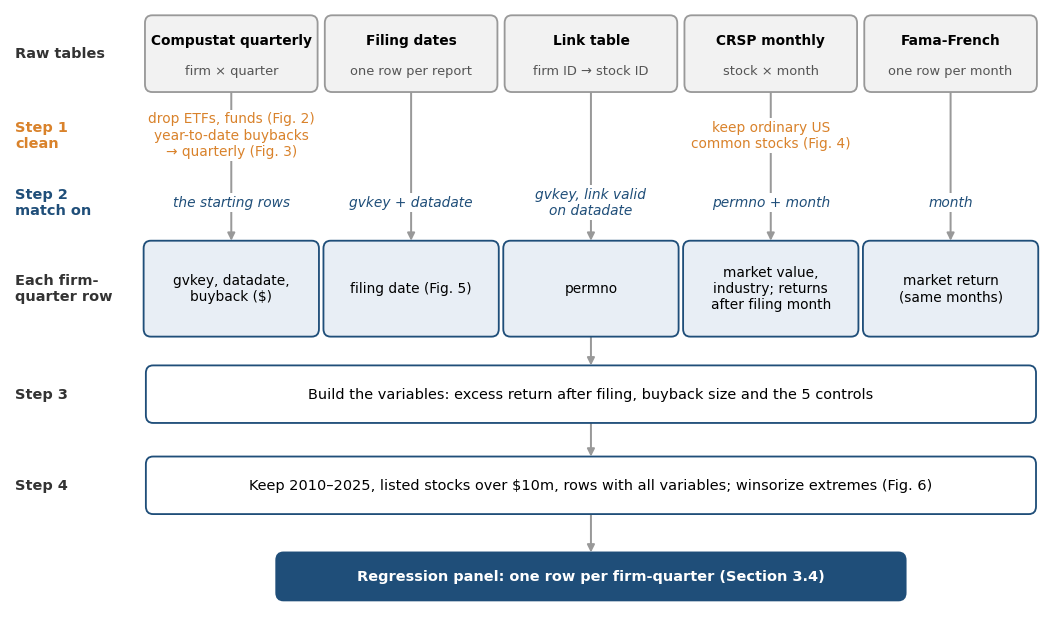

In [5]:
from matplotlib.patches import FancyBboxPatch

TABLES = [  # name, shape, Step 1: what we clean, Step 2: matched on, what it adds to each firm-quarter row
    ("Compustat quarterly", "firm × quarter", "drop ETFs, funds (Fig. 2)\nyear-to-date buybacks\n→ quarterly (Fig. 3)",
     "the starting rows", "gvkey, datadate,\nbuyback ($)"),
    ("Filing dates", "one row per report", "", "gvkey + datadate", "filing date (Fig. 5)"),
    ("Link table", "firm ID → stock ID", "", "gvkey, link valid\non datadate", "permno"),
    ("CRSP monthly", "stock × month", "keep ordinary US\ncommon stocks (Fig. 4)", "permno + month",
     "market value,\nindustry; returns\nafter filing month"),
    ("Fama-French", "one row per month", "", "month", "market return\n(same months)"),
]
Y_RAW, Y_CLEAN, Y_MATCH, Y_ROW, Y_S3, Y_S4, Y_PANEL = 5.85, 5.0, 4.3, 3.4, 2.3, 1.35, 0.4

fig = plt.figure(figsize=(9.4, 5.45))
ax = fig.add_axes([0, 0, 1, 1])                                    # a drawing, so use the whole figure
ax.set_xlim(-1.45, 10.05)
ax.set_ylim(0.05, 6.3)
ax.axis("off")


def box(x, y, w, h, face, edge, text="", **kw):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.08",
                                fc=face, ec=edge, lw=1.2, zorder=2))
    ax.text(x, y, text, ha="center", va="center", fontsize=kw.pop("fontsize", 9.5), zorder=3, **kw)


def arrow(x, y0, y1):
    ax.annotate("", xy=(x, y1), xytext=(x, y0), zorder=1,
                arrowprops=dict(arrowstyle="-|>", color=GREY, lw=1.3, shrinkA=0, shrinkB=0))


for k, (name, shape, clean, key, adds) in enumerate(TABLES):
    x = 1 + 2 * k
    box(x, Y_RAW, 1.92, 0.8, "#f2f2f2", GREY)
    ax.text(x, Y_RAW + 0.14, name, ha="center", va="center", fontsize=9, weight="bold", zorder=3)
    ax.text(x, Y_RAW - 0.18, shape, ha="center", va="center", fontsize=8.5, color="#555555", zorder=3)
    arrow(x, Y_RAW - 0.4, Y_ROW + 0.5)
    for y, text, colour, style in [(Y_CLEAN, clean, ORANGE, "normal"), (Y_MATCH, key, NAVY, "italic")]:
        if text:
            ax.text(x, y, text, ha="center", va="center", fontsize=9, color=colour, style=style, zorder=3,
                    bbox=dict(fc="white", ec="none", pad=1.5))
    box(x, Y_ROW, 1.95, 1.0, "#e8eef5", NAVY, adds, fontsize=9)

for y, text, colour in [(Y_RAW, "Raw tables", "#333333"), (Y_CLEAN, "Step 1\nclean", ORANGE),
                        (Y_MATCH, "Step 2\nmatch on", NAVY), (Y_ROW, "Each firm-\nquarter row", "#333333"),
                        (Y_S3, "Step 3", "#333333"), (Y_S4, "Step 4", "#333333")]:
    ax.text(-1.4, y, text, ha="left", va="center", fontsize=9.5, weight="bold", color=colour)

arrow(5, Y_ROW - 0.5, Y_S3 + 0.3)
box(5, Y_S3, 9.9, 0.6, "white", NAVY, "Build the variables: excess return after filing, buyback size and the 5 controls")
arrow(5, Y_S3 - 0.3, Y_S4 + 0.3)
box(5, Y_S4, 9.9, 0.6, "white", NAVY,
    r"Keep 2010–2025, listed stocks over \$10m, rows with all variables; winsorize extremes (Fig. 6)")
arrow(5, Y_S4 - 0.3, Y_PANEL + 0.25)
box(5, Y_PANEL, 7.0, 0.5, NAVY, NAVY, "Regression panel: one row per firm-quarter (Section 3.4)",
    color="white", weight="bold")
plt.show()

### Step 1: Clean each table
**(a) Compustat: keep firms with company accounts.** About a third of the rows have no total assets, and these rows also miss the other accounting items (report Figure 2). The 10 random examples below show that they are mostly ETFs and funds. We keep rows with total assets > 0 and drop duplicated quarters (firms that changed their fiscal year-end).

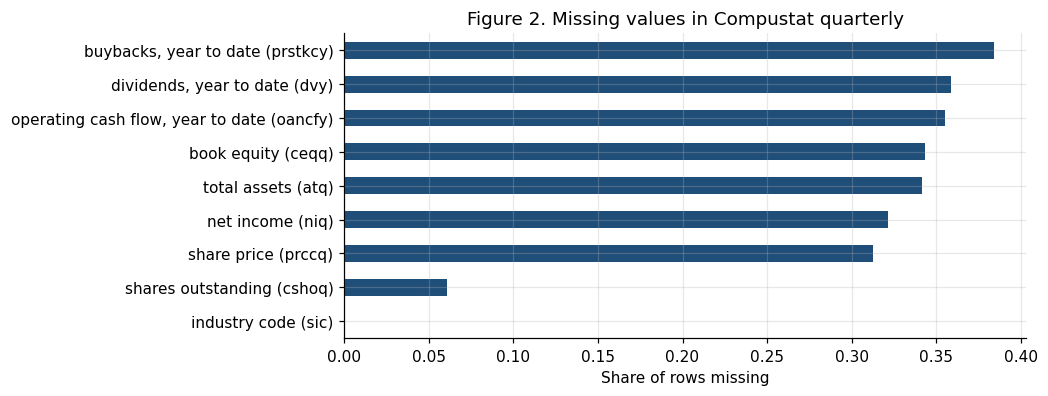

,quarter end,shares outstanding (cshoq),total assets (atq),net income (niq)
company,,,,
GLOBAL X FOUNDER-RUN COM ETF,2022-06-30,0.380,<NA>,<NA>
SUNAMERICA FOCSD ALPHA LG-CP,2010-06-30,9.655,<NA>,<NA>
WESTERN AST INV GRD OP TR IN,2025-03-31,5.994,<NA>,<NA>
ISHARES 1-3 YR TREAS BD ETF,2012-05-31,135.400,<NA>,<NA>
STATE STRT SPDR BLMBG INT CR,2014-06-30,8.400,<NA>,<NA>
AVIDXCHANGE HOLDINGS INC,2019-06-30,<NA>,<NA>,-18.180
INVESCO SOLAR ETF,2020-09-30,24.008,<NA>,<NA>
EATON VANCE TX-MGD GLBL B-W,2015-09-30,106.443,<NA>,<NA>
FORT DEARBORN INCOME SECS,2011-06-30,8.776,<NA>,<NA>


In [6]:
# the Compustat variables we use, with plain names
FUNDQ_NAMES = {"cshoq": "shares outstanding", "prccq": "share price", "atq": "total assets", "niq": "net income",
               "ceqq": "book equity", "oancfy": "operating cash flow, year to date",
               "prstkcy": "buybacks, year to date", "dvy": "dividends, year to date", "sic": "industry code"}
miss = fundq_raw[list(FUNDQ_NAMES)].isna().mean().sort_values()
miss.index = [f"{FUNDQ_NAMES[c]} ({c})" for c in miss.index]
fig, ax = plt.subplots(figsize=(8, 3.6))
miss.plot.barh(ax=ax, color=NAVY)
ax.set_xlabel("Share of rows missing")
ax.set_title("Figure 2. Missing values in Compustat quarterly")
plt.show()
no_accounts = fundq_raw.loc[fundq_raw["atq"].isna(), ["conm", "datadate", "cshoq", "atq", "niq"]].sample(10, random_state=3)
no_accounts["datadate"] = no_accounts["datadate"].dt.date
no_accounts.columns = ["company", "quarter end", "shares outstanding (cshoq)", "total assets (atq)", "net income (niq)"]
no_accounts.set_index("company")

In [7]:
q = to_float(fundq_raw)
log_step("Compustat quarterly, US firms, 2008-2025", q)
q = q[q["atq"] > 0]                                                # drop ETFs / funds without accounts
dup = (q.duplicated(["gvkey", "datadate"], keep=False) | q.duplicated(["gvkey", "fyearq", "fqtr"], keep=False)
       | q["fqtr"].isna())
q = q[~dup].copy()
log_step("Has company accounts (total assets > 0)", q)
print(f"Compustat firm-quarters: {len(fundq_raw):,} -> {len(q):,} with company accounts")

Compustat firm-quarters: 601,610 -> 393,074 with company accounts


**(b) Turn year-to-date buybacks into quarterly buybacks.** `prstkcy` is a running total for the fiscal year (report Figure 3, Apple). The quarter's buyback is `prstkcy` in fiscal Q1, and `prstkcy` minus the previous quarter's value otherwise. A blank buyback from a firm that reports a cash flow statement counts as 0. Negative results (restatements, under 1% of rows) are set to missing.

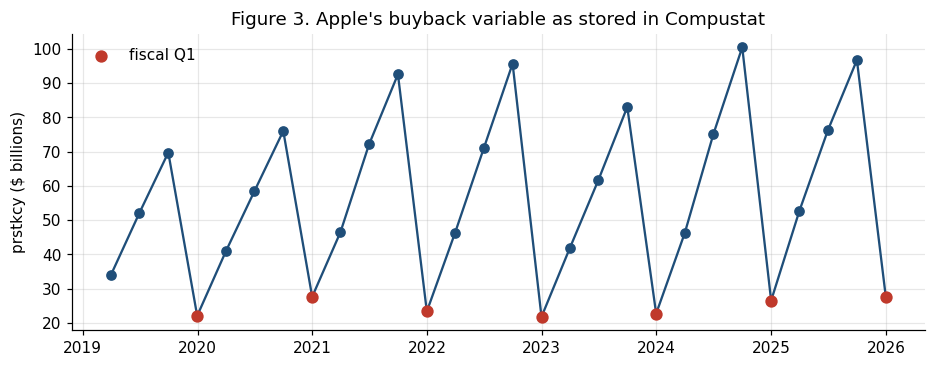

In [8]:
aapl = fundq_raw[(fundq_raw["tic"] == "AAPL") & (fundq_raw["datadate"] >= "2019-01-01")].sort_values("datadate")
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(aapl["datadate"], aapl["prstkcy"].astype(float) / 1e3, marker="o", color=NAVY)
fq1 = aapl[aapl["fqtr"] == 1]
ax.scatter(fq1["datadate"], fq1["prstkcy"].astype(float) / 1e3, color="#c0392b", zorder=3, s=50, label="fiscal Q1")
ax.set_ylabel("prstkcy ($ billions)")
ax.set_title("Figure 3. Apple's buyback variable as stored in Compustat")
ax.legend(frameon=False)
plt.show()

In [9]:
has_cfs = q["oancfy"].notna()                                      # firm reported a cash flow statement
q.loc[has_cfs & q["prstkcy"].isna(), "prstkcy"] = 0

q = q.sort_values(["gvkey", "fyearq", "fqtr"]).reset_index(drop=True)
g = q.groupby("gvkey")
prev_is_last_quarter = (g["fyearq"].shift(1) == q["fyearq"]) & (g["fqtr"].shift(1) == q["fqtr"] - 1)
q["bb_q"] = np.where(q["fqtr"] == 1, q["prstkcy"],
                     np.where(prev_is_last_quarter, q["prstkcy"] - g["prstkcy"].shift(1), np.nan))
q.loc[q["bb_q"] < 0, "bb_q"] = np.nan                              # restatements

# calendar-quarter counter, so that "last quarter" really means the previous quarter
q = q.sort_values(["gvkey", "datadate"]).reset_index(drop=True)
q["cal_q"] = q["datadate"].dt.to_period("Q")
q["qidx"] = q["datadate"].dt.year * 4 + q["datadate"].dt.quarter
q = q.drop_duplicates(["gvkey", "qidx"], keep="last").reset_index(drop=True)


def lag(df, col, k=1):
    """Value of `col` k quarters earlier for the same firm, or missing if that quarter is not in the data."""
    grp = df.groupby("gvkey")
    exact = (df["qidx"] - grp["qidx"].shift(k)) == k
    return grp[col].shift(k).where(exact)

**(c) CRSP: keep ordinary shares of US companies** listed on the NYSE, NYSE American or NASDAQ (report Figure 4). The rest are mostly ETFs, funds, ADRs and REITs.

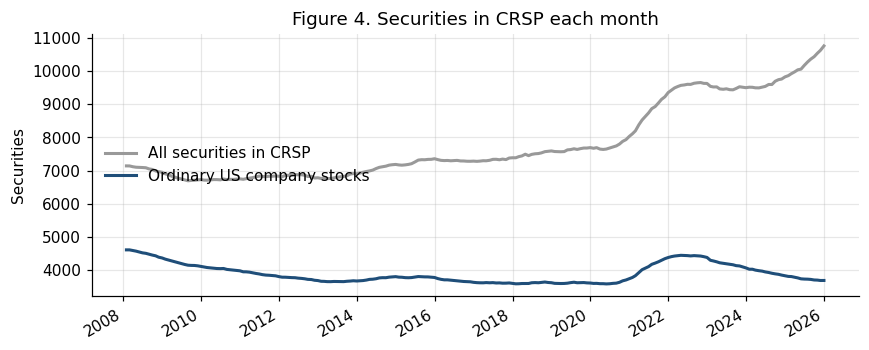

In [10]:
common = ((msf_raw["sharetype"] == "NS") & (msf_raw["securitytype"] == "EQTY") & (msf_raw["securitysubtype"] == "COM")
          & (msf_raw["usincflg"] == "Y") & msf_raw["issuertype"].isin(["ACOR", "CORP"])
          & msf_raw["primaryexch"].isin(["N", "A", "Q"]))
counts = pd.DataFrame({"All securities in CRSP": msf_raw.groupby("mthcaldt")["permno"].nunique(),
                       "Ordinary US company stocks": msf_raw[common].groupby("mthcaldt")["permno"].nunique()})
fig, ax = plt.subplots(figsize=(9, 3.5))
counts.plot(ax=ax, color=[GREY, NAVY], lw=2)
ax.set_xlabel("")
ax.set_ylabel("Securities")
ax.set_title("Figure 4. Securities in CRSP each month")
ax.legend(frameon=False, loc="center left")
plt.show()

In [11]:
m = to_float(msf_raw[common])                                      # ordinary US common stocks only
m["ym"] = m["mthcaldt"].dt.to_period("M")
print(f"CRSP security-months: {len(msf_raw):,} -> {len(m):,} ordinary US common stocks")

CRSP security-months: 1,686,282 -> 841,097 ordinary US common stocks


### Step 2: Merge the tables
**(a) Filing date.** A quarter's buyback becomes public when its 10-Q or 10-K is filed (report Figure 5). We keep the first filing for each quarter and drop impossible dates (on or before the quarter end, or more than 180 days after it).

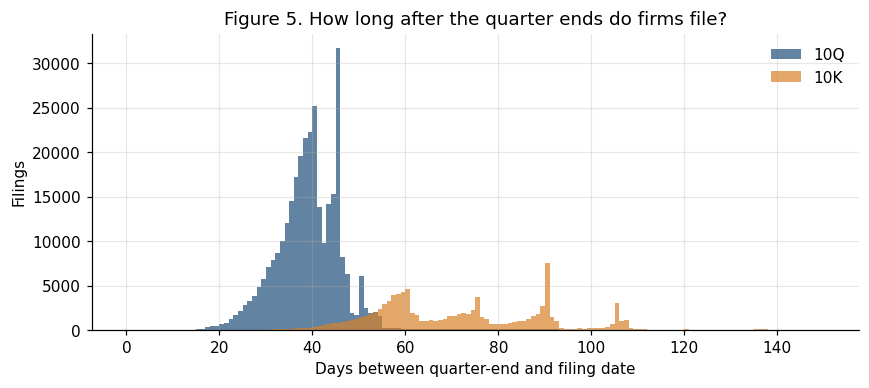

In [12]:
lag_days = (filedates_raw["filedate"] - filedates_raw["datadate"]).dt.days
fig, ax = plt.subplots(figsize=(9, 3.5))
for form, colour in [("10Q", NAVY), ("10K", ORANGE)]:
    ax.hist(lag_days[(filedates_raw["srctype"] == form) & lag_days.between(0, 150)], bins=150, alpha=0.7,
            color=colour, label=form)
ax.set_xlabel("Days between quarter-end and filing date")
ax.set_ylabel("Filings")
ax.set_title("Figure 5. How long after the quarter ends do firms file?")
ax.legend(frameon=False)
plt.show()

In [13]:
fd = filedates_raw.sort_values("filedate").drop_duplicates(["gvkey", "datadate"], keep="first").copy()
fd["file_lag"] = (fd["filedate"] - fd["datadate"]).dt.days
fd = fd[(fd["file_lag"] >= 1) & (fd["file_lag"] <= 180)]
q = q.merge(fd[["gvkey", "datadate", "filedate", "file_lag"]], on=["gvkey", "datadate"], how="left")

recent = q["datadate"] >= "2010-01-01"
print(f"Median days from quarter-end to filing: {q.loc[recent, 'file_lag'].median():.0f}")
print(f"Firm-quarters (2010+) with a filing date: {q.loc[recent, 'filedate'].notna().mean():.1%}")

Median days from quarter-end to filing: 40
Firm-quarters (2010+) with a filing date: 92.6%


**(b) Stock, market value and industry.** Link `gvkey` to `permno` using the link that is valid on the quarter-end date (the main share class first), take that stock's CRSP row in the quarter-end month, and group the SIC code into the Fama-French 12 industries.

In [14]:
# link Compustat firm-quarters to CRSP stocks (valid link dates, primary link first)
link = to_float(ccm_raw)
link["linkenddt"] = link["linkenddt"].fillna(pd.Timestamp("2100-12-31"))
lk = q[["gvkey", "datadate"]].merge(link, on="gvkey")
lk = lk[(lk["datadate"] >= lk["linkdt"]) & (lk["datadate"] <= lk["linkenddt"])]
lk = lk.sort_values(["gvkey", "datadate", "linkprim"], key=lambda s: s.map({"P": 0, "C": 1}) if s.name == "linkprim" else s)
lk = lk.drop_duplicates(["gvkey", "datadate"])
q = q.merge(lk[["gvkey", "datadate", "permno"]], on=["gvkey", "datadate"], how="left")
q["ym"] = q["datadate"].dt.to_period("M")
q = q.merge(m[["permno", "ym", "mthcap", "mthprc", "siccd"]], on=["permno", "ym"], how="left")

# Fama-French 12 industries from the SIC code (CRSP's code at the time; Compustat's if missing)
FF12 = {
    "Consumer NonDurables": [(100, 999), (2000, 2399), (2700, 2749), (2770, 2799), (3100, 3199), (3940, 3989)],
    "Consumer Durables": [(2500, 2519), (2590, 2599), (3630, 3659), (3710, 3711), (3714, 3714), (3716, 3716),
                          (3750, 3751), (3792, 3792), (3900, 3939), (3990, 3999)],
    "Manufacturing": [(2520, 2589), (2600, 2699), (2750, 2769), (3000, 3099), (3200, 3569), (3580, 3629),
                      (3700, 3709), (3712, 3713), (3715, 3715), (3717, 3749), (3752, 3791), (3793, 3799),
                      (3830, 3839), (3860, 3899)],
    "Energy": [(1200, 1399), (2900, 2999)],
    "Chemicals": [(2800, 2829), (2840, 2899)],
    "Business Equipment (Tech)": [(3570, 3579), (3660, 3692), (3694, 3699), (3810, 3829), (7370, 7379)],
    "Telecom": [(4800, 4899)],
    "Utilities": [(4900, 4949)],
    "Shops (Retail)": [(5000, 5999), (7200, 7299), (7600, 7699)],
    "Healthcare": [(2830, 2839), (3693, 3693), (3840, 3859), (8000, 8099)],
    "Finance": [(6000, 6999)],
}


def ff12(sic):
    if pd.isna(sic):
        return np.nan
    for name, ranges in FF12.items():
        if any(lo <= sic <= hi for lo, hi in ranges):
            return name
    return "Other"


q["sic_use"] = q["siccd"].where(q["siccd"] > 0, pd.to_numeric(q["sic"], errors="coerce"))
q["industry"] = q["sic_use"].map({s: ff12(s) for s in q["sic_use"].dropna().unique()})
print(f"Compustat firm-quarters matched to a CRSP common stock: {q['mthcap'].notna().mean():.1%}")

Compustat firm-quarters matched to a CRSP common stock: 67.9%


### Step 3: Build the variables
- **3-month excess return (the outcome):** the stock's buy-and-hold return over the 3 months after the filing month, minus the market's buy-and-hold return over the same months. The stock must trade in the first month. If it stops trading later in the window (for example, it is delisted), the money is assumed to sit in the market for the remaining months. The 12-month version is used as a robustness check.
- **Buyback size:** 100 × the quarter's buyback / market value at the start of the quarter.
- **Controls:** log size, book-to-market, past 12-month return, ROA and asset growth (report Table 7).

In [15]:
ff = to_float(ff_raw)
ff["ym"] = ff["date"].dt.to_period("M")
ff["mkt"] = ff["mktrf"] + ff["rf"]                                 # market return = excess market return + risk-free

# buy-and-hold returns after the filing month (3 and 12 months) and over the past 12 months
ret_lookup = m.set_index(["permno", "ym"])["mthret"]
mkt_lookup = ff.set_index("ym")["mkt"]


def buy_and_hold(df, month_col, k_from, k_to):
    """Compound stock and market returns over months [month + k_from, month + k_to].
    Returns (stock return, excess return). The stock must trade in the first month."""
    stock, market, first_ok = np.ones(len(df)), np.ones(len(df)), None
    for k in range(k_from, k_to + 1):
        months = df[month_col] + k
        r = ret_lookup.reindex(pd.MultiIndex.from_arrays([df["permno"], months])).to_numpy(dtype=float)
        mk = mkt_lookup.reindex(months).to_numpy(dtype=float)
        if first_ok is None:
            first_ok = ~np.isnan(r)
        r = np.where(np.isnan(r), mk, r)                          # after delisting: money held in the market
        stock *= 1 + r
        market *= 1 + mk
    return np.where(first_ok, stock - 1, np.nan), np.where(first_ok, stock - market, np.nan)


qs = q.loc[q["mthcap"].notna(), ["gvkey", "datadate", "permno", "ym", "filedate"]].copy()
qs["permno"] = qs["permno"].astype(int)
qs["file_ym"] = qs["filedate"].dt.to_period("M")
dated = qs["file_ym"].notna()
for h in (3, 12):
    qs[f"exret{h}"] = np.nan
    qs.loc[dated, f"exret{h}"] = buy_and_hold(qs[dated], "file_ym", 1, h)[1]
qs["past_ret12"] = buy_and_hold(qs, "ym", -11, 0)[0]
q = q.merge(qs[["gvkey", "datadate", "exret3", "exret12", "past_ret12"]], on=["gvkey", "datadate"], how="left")

In [16]:
q["mcap"] = q["prccq"] * q["cshoq"]                                # market value, $ millions
q["mcap_lag"] = lag(q, "mcap", 1)
q["intensity"] = 100 * q["bb_q"] / q["mcap_lag"]                   # buyback size, % of market value
q["log_mcap"] = np.log(q["mcap_lag"].where(q["mcap_lag"] > 0))
q["bm"] = (q["ceqq"] / q["mcap"]).where(q["ceqq"] > 0)            # only meaningful with positive book equity
q["roa"] = q["niq"] / q["atq"]
q["asset_growth"] = q["atq"] / lag(q, "atq", 4) - 1
q["div_payer"] = (q["dvy"] > 0).astype(float).where(q["dvy"].notna())
q = q.replace([np.inf, -np.inf], np.nan)

### Step 4: Choose the final sample and handle outliers
Keep quarter-ends from 2010 to 2025, CRSP-listed common stocks, and firms worth more than $10 million at the start of the quarter.

In [17]:
CONTROLS = ["log_mcap", "bm_w", "past_ret12_w", "roa_w", "asset_growth_w"]
Y = "exret3_pct"                                                   # main outcome: 3-month excess return, %

panel = q[(q["datadate"] >= "2010-01-01") & (q["datadate"] <= "2025-12-31")]
log_step("Quarter-end in 2010-2025", panel)
panel = panel[panel["mthcap"].notna()]
log_step("CRSP-listed US common stock", panel)
panel = panel[(panel["mcap_lag"] > 10) & panel["intensity"].notna()].copy()
log_step("Market value > $10m and buyback size known", panel)

**Report Figure 6.** A few 3-month returns are extreme. We therefore winsorize the returns and the controls (except size) at their 1st and 99th percentiles, and buyback size at its 99th percentile. The dashed lines are the return cut-offs.

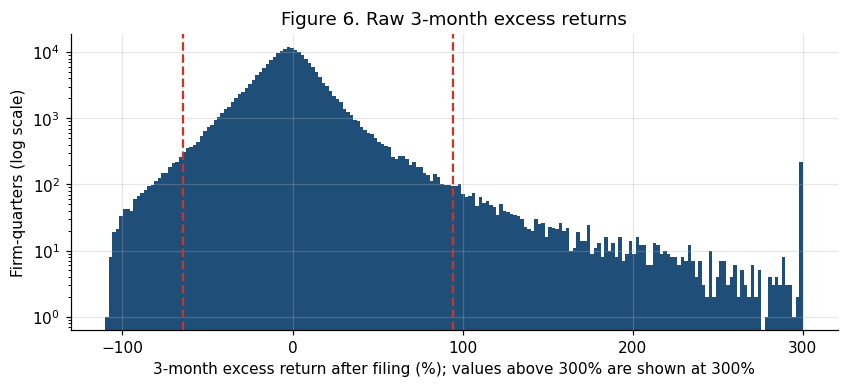

1st percentile: -65%   99th percentile: 94%   largest: 3,322%


In [18]:
r3 = 100 * panel["exret3"].dropna()
p1, p99 = r3.quantile([0.01, 0.99])
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(r3.clip(upper=300), bins=200, color=NAVY)
for v in (p1, p99):
    ax.axvline(v, color="#c0392b", ls="--")
ax.set_yscale("log")
ax.set_xlabel("3-month excess return after filing (%); values above 300% are shown at 300%")
ax.set_ylabel("Firm-quarters (log scale)")
ax.set_title("Figure 6. Raw 3-month excess returns")
plt.show()
print(f"1st percentile: {p1:.0f}%   99th percentile: {p99:.0f}%   largest: {r3.max():,.0f}%")

In [19]:
panel["bb_size"] = winsorize(panel["intensity"], 0, 0.99)
for c in ["exret3", "exret12", "past_ret12", "bm", "roa", "asset_growth"]:
    panel[c + "_w"] = winsorize(panel[c])
panel["exret3_pct"] = 100 * panel["exret3_w"]
panel["exret12_pct"] = 100 * panel["exret12_w"]
SIZE_GROUPS = ["None", "Small (0-0.5%)", "Medium (0.5-2%)", "Large (>2%)"]
panel["size_group"] = pd.cut(panel["intensity"], [-np.inf, 0, 0.5, 2, np.inf], labels=SIZE_GROUPS)
panel["any_bb"] = (panel["intensity"] > 0).astype(float)
for grp_name, col in zip(SIZE_GROUPS[1:], ["g_small", "g_medium", "g_large"]):
    panel[col] = (panel["size_group"] == grp_name).astype(float)
panel["entity"] = panel["gvkey"]

sample = panel.dropna(subset=["exret3_pct", "industry"] + CONTROLS).copy()
log_step("Has a 3-month return and all controls (regression sample)", sample)

Firm-quarters and firms left after each filter. The regression sample ends in 2025Q3, because later quarters do not yet have a full 3-month return window.

In [20]:
pd.DataFrame(sample_log).set_index("step")

,firm-quarters,firms
step,,
"Compustat quarterly, US firms, 2008-2025",601610,19469
Has company accounts (total assets > 0),393074,12068
Quarter-end in 2010-2025,343819,11033
CRSP-listed US common stock,233604,7519
Market value > $10m and buyback size known,222258,7397
Has a 3-month return and all controls (regression sample),191972,6839


## 4. The final panel (report Section 3.4)
**Report Table 8.** A few rows of the panel: Apple and, for comparison, Verizon (no buybacks in these quarters). Only the columns used in the regressions are kept.

In [21]:
PANEL_COLS = {"cal_q": "quarter", Y: "3-month excess return (%)", "bb_size": "buyback size (%)",
              "log_mcap": "log size", "bm_w": "book-to-market", "past_ret12_w": "past 12m return", "roa_w": "ROA",
              "asset_growth_w": "asset growth", "industry": "industry"}
rows = sample[sample["tic"].isin(["AAPL", "VZ"]) & sample["datadate"].between("2023-10-01", "2024-06-30")]
rows = rows.assign(firm=rows["tic"].map({"AAPL": "Apple", "VZ": "Verizon"})).set_index("firm")
rows[list(PANEL_COLS)].rename(columns=PANEL_COLS)

,quarter,3-month excess return (%),buyback size (%),log size,book-to-market,past 12m return,ROA,asset growth,industry
firm,,,,,,,,,
Apple,2023Q4,2.844,0.854,14.795,0.025,0.490,0.096,0.020,Business Equipment (Tech)
Apple,2024Q1,12.126,0.789,14.906,0.028,0.045,0.070,0.016,Business Equipment (Tech)
Apple,2024Q2,-4.749,1.095,14.783,0.022,0.092,0.065,-0.010,Business Equipment (Tech)
Verizon,2023Q4,0.834,0.000,11.822,0.583,0.028,-0.007,0.002,Telecom
Verizon,2024Q1,-5.659,0.000,11.974,0.534,0.160,0.012,0.006,Telecom
Verizon,2024Q2,1.985,0.000,12.082,0.554,0.192,0.012,-0.002,Telecom


## 5. Descriptive evidence (report Section 4)
**Report Figures 7 & 8.** The share of firms that buy back in each quarter, and the total dollars spent. The printed lines give the numbers quoted in Section 4.1.

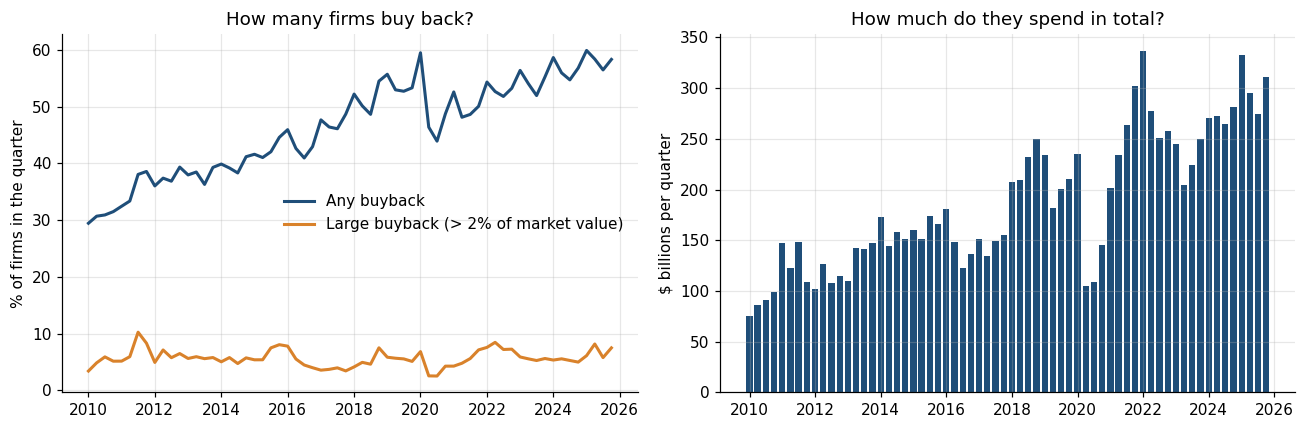

Firms buying back in an average quarter: 31% in 2010 -> 58% in 2025
Total spending: $350bn in 2010 -> $1,088bn in 2024
Median buyback, when a firm buys back: 0.31% of market value
Share of all buyback dollars spent by the top 1% of firms (average year): 51%


In [22]:
by_q = panel.groupby("cal_q").agg(pct_any=("any_bb", lambda s: 100 * s.mean()),
                                  pct_large=("intensity", lambda s: 100 * (s > 2).mean()),
                                  total_bn=("bb_q", lambda s: s.sum() / 1e3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
x = by_q.index.to_timestamp()
ax[0].plot(x, by_q["pct_any"], color=NAVY, lw=2, label="Any buyback")
ax[0].plot(x, by_q["pct_large"], color=ORANGE, lw=2, label="Large buyback (> 2% of market value)")
ax[0].set_ylabel("% of firms in the quarter")
ax[0].set_title("How many firms buy back?")
ax[0].legend(frameon=False)
ax[1].bar(x, by_q["total_bn"], width=70, color=NAVY)
ax[1].set_ylabel("$ billions per quarter")
ax[1].set_title("How much do they spend in total?")
plt.tight_layout()
plt.show()

buyers = panel[panel["intensity"] > 0]
spend = panel.groupby(["gvkey", panel["datadate"].dt.year])["bb_q"].sum()
top1 = spend.groupby(level=1).apply(lambda s: s.nlargest(max(1, len(s) // 100)).sum() / s.sum()).mean()
yearly = by_q.groupby(by_q.index.year).agg(pct_any=("pct_any", "mean"), total_bn=("total_bn", "sum"))
print(f"Firms buying back in an average quarter: {yearly.loc[2010, 'pct_any']:.0f}% in 2010 -> {yearly.loc[2025, 'pct_any']:.0f}% in 2025")
print(f"Total spending: ${yearly.loc[2010, 'total_bn']:,.0f}bn in 2010 -> ${yearly.loc[2024, 'total_bn']:,.0f}bn in 2024")
print(f"Median buyback, when a firm buys back: {buyers['intensity'].median():.2f}% of market value")
print(f"Share of all buyback dollars spent by the top 1% of firms (average year): {top1:.0%}")

**Summary statistics of the regression sample.** Not tabulated in the report; the means for quarters with and without a buyback support Sections 4.2 and 7.1.

In [23]:
T1 = {"bb_size": "Buyback size (% of mkt value)", "exret3_pct": "3-month excess return (%)",
      "exret12_pct": "12-month excess return (%)", "log_mcap": "log market value ($m)",
      "bm_w": "Book-to-market", "past_ret12_w": "Past 12-month return", "roa_w": "ROA (quarterly)",
      "asset_growth_w": "Asset growth (yearly)", "div_payer": "Pays a dividend (0/1)"}
table1 = sample[list(T1)].describe().T[["mean", "std", "25%", "50%", "75%"]]
table1["mean: buyback quarters"] = sample.loc[sample["any_bb"] == 1, list(T1)].mean()
table1["mean: no buyback"] = sample.loc[sample["any_bb"] == 0, list(T1)].mean()
table1.index = list(T1.values())
print(f"Regression sample: {len(sample):,} firm-quarters ({(sample['any_bb'] == 1).sum():,} with a buyback, "
      f"{(sample['any_bb'] == 0).sum():,} without)")
table1

Regression sample: 191,972 firm-quarters (92,309 with a buyback, 99,663 without)


,mean,std,25%,50%,75%,mean: buyback quarters,mean: no buyback
Buyback size (% of mkt value),0.395,0.926,0.000,0.000,0.284,0.821,0.000
3-month excess return (%),-1.142,22.754,-12.701,-1.988,8.539,-0.515,-1.723
12-month excess return (%),-4.181,49.852,-32.167,-7.238,15.706,-1.960,-6.186
log market value ($m),6.689,2.134,5.109,6.639,8.138,7.476,5.960
Book-to-market,0.642,0.561,0.259,0.501,0.851,0.588,0.693
Past 12-month return,0.132,0.565,-0.191,0.067,0.335,0.142,0.124
ROA (quarterly),-0.014,0.072,-0.010,0.003,0.016,0.004,-0.031
Asset growth (yearly),0.129,0.435,-0.030,0.045,0.154,0.104,0.153
Pays a dividend (0/1),0.444,0.497,0.000,0.000,1.000,0.542,0.353


**Report Figure 9.** The average 3-month excess return by buyback size group, with 95% confidence intervals.

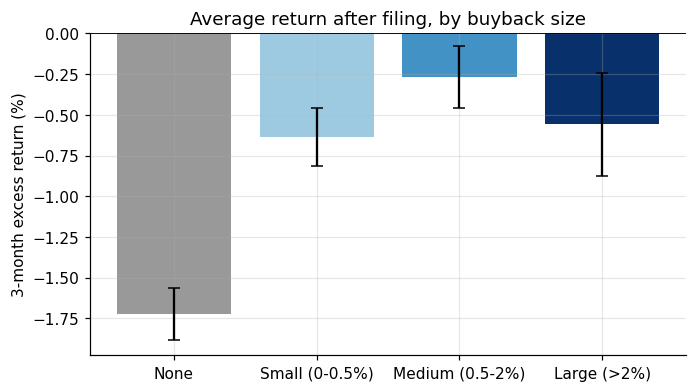

,mean (%),95% CI low,95% CI high,firm-quarters
size_group,,,,
None,-1.723,-1.882,-1.564,99663
Small (0-0.5%),-0.634,-0.811,-0.456,53570
Medium (0.5-2%),-0.265,-0.456,-0.074,27479
Large (>2%),-0.559,-0.877,-0.241,11260


In [24]:
def mean_ci(s):
    s = s.dropna()
    se = s.std() / np.sqrt(len(s))
    return pd.Series({"mean (%)": s.mean(), "95% CI low": s.mean() - 1.96 * se, "95% CI high": s.mean() + 1.96 * se,
                      "firm-quarters": len(s)})


raw = sample.groupby("size_group", observed=True)[Y].apply(mean_ci).unstack()
raw["firm-quarters"] = raw["firm-quarters"].astype(int)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(range(4), raw["mean (%)"], color=[GREY, "#9ecae1", "#4292c6", "#08306b"],
       yerr=[raw["mean (%)"] - raw["95% CI low"], raw["95% CI high"] - raw["mean (%)"]], capsize=4)
ax.set_xticks(range(4), raw.index)
ax.axhline(0, color="black", lw=0.6)
ax.set_ylabel("3-month excess return (%)")
ax.set_title("Average return after filing, by buyback size")
plt.show()
raw

## 6. Regressions (report Sections 5 and 6)
Panel OLS with firm, quarter or industry fixed effects. Standard errors are clustered by firm and by quarter. Stars: \* p<0.10, \*\* p<0.05, \*\*\* p<0.01.

In [25]:
def panel_fit(data, y, xs, firm_fe=False, quarter_fe=False, industry_fe=False, weights=None):
    """Panel OLS with optional firm / quarter / industry fixed effects; two-way clustered (firm, quarter) s.e."""
    use = data.dropna(subset=[y] + xs).set_index(["entity", "qidx"])
    exog = use[xs] if (firm_fe or quarter_fe or industry_fe) else sm.add_constant(use[xs])
    model = PanelOLS(use[y], exog, entity_effects=firm_fe, time_effects=quarter_fe,
                     other_effects=use[["industry"]] if industry_fe else None,
                     weights=use[weights] if weights else None)
    return model.fit(cov_type="clustered", cluster_entity=True, cluster_time=True)


def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""


def reg_table(models, show=None):
    """Side-by-side regression table: coefficient (stars) with standard error below; N, R-squared, fixed effects."""
    show = show or list(dict.fromkeys(v for r in models.values() for v in r.params.index if v != "const"))
    table = {}
    for name, r in models.items():
        col = {}
        for v in show:
            lab = LABELS.get(v, v)
            col[lab] = f"{r.params[v]:.3f}{stars(r.pvalues[v])}" if v in r.params.index else ""
            col[lab + " "] = f"({r.std_errors[v]:.3f})" if v in r.params.index else ""
        col["Observations"] = f"{int(r.nobs):,}"
        col["R-squared"] = f"{r.rsquared:.4f}"
        col["Firm FE"] = "yes" if r.model.entity_effects else ""
        col["Quarter FE"] = "yes" if r.model.time_effects else ""
        col["Industry FE"] = "yes" if r.model.other_effects else ""
        table[name] = col
    return pd.DataFrame(table)


LABELS = {"bb_size": "Buyback size (% of mkt value)", "log_mcap": "Log size", "bm_w": "Book-to-market",
          "past_ret12_w": "Past 12m return", "roa_w": "ROA", "asset_growth_w": "Asset growth",
          "g_small": "Small buyback (0-0.5%)", "g_medium": "Medium buyback (0.5-2%)", "g_large": "Large buyback (>2%)"}
GROUPS = ["g_small", "g_medium", "g_large"]

**Report Table 9.** Buyback size and 3-month excess returns, adding the controls and fixed effects one step at a time. The next cell prints the 95% confidence intervals and the one-standard-deviation effect quoted in Section 6.1.1.

In [26]:
main_models = {
    "(1) No controls": panel_fit(sample, Y, ["bb_size"]),
    "(2) + Controls": panel_fit(sample, Y, ["bb_size"] + CONTROLS),
    "(3) + Quarter & industry FE": panel_fit(sample, Y, ["bb_size"] + CONTROLS, quarter_fe=True, industry_fe=True),
    "(4) Firm & quarter FE": panel_fit(sample, Y, ["bb_size"] + CONTROLS, firm_fe=True, quarter_fe=True),
}
reg_table(main_models)

,(1) No controls,(2) + Controls,(3) + Quarter & industry FE,(4) Firm & quarter FE
Buyback size (% of mkt value),0.308,-0.032,0.043,0.012
Buyback size (% of mkt value),(0.189),(0.121),(0.111),(0.094)
Log size,,0.110,0.198**,-4.537***
Log size,,(0.091),(0.096),(0.488)
Book-to-market,,0.455,0.654*,1.953***
Book-to-market,,(0.465),(0.395),(0.524)
Past 12m return,,0.342,1.032**,-0.526
Past 12m return,,(0.547),(0.411),(0.382)
ROA,,23.271***,22.134***,6.948***
ROA,,(4.970),(4.113),(2.337)


In [27]:
sd_bb = sample.loc[sample["bb_size"] > 0, "bb_size"].std()
for name in ["(3) + Quarter & industry FE", "(4) Firm & quarter FE"]:
    r = main_models[name]
    b, se = r.params["bb_size"], r.std_errors["bb_size"]
    print(f"{name}: 95% CI for the buyback coefficient [{b - 1.96 * se:.2f}, {b + 1.96 * se:.2f}]; "
          f"a one-s.d. bigger buyback ({sd_bb:.1f}% of market value) -> {b * sd_bb:+.2f} pp over 3 months")

(3) + Quarter & industry FE: 95% CI for the buyback coefficient [-0.17, 0.26]; a one-s.d. bigger buyback (1.2% of market value) -> +0.05 pp over 3 months
(4) Firm & quarter FE: 95% CI for the buyback coefficient [-0.17, 0.20]; a one-s.d. bigger buyback (1.2% of market value) -> +0.01 pp over 3 months


**Report Table 10.** Buyback size groups, each compared with quarters with no buyback. The report shows only the group coefficients; the control coefficients are printed here as well.

In [28]:
group_models = {
    "(1) Quarter & industry FE": panel_fit(sample, Y, GROUPS + CONTROLS, quarter_fe=True, industry_fe=True),
    "(2) Firm & quarter FE": panel_fit(sample, Y, GROUPS + CONTROLS, firm_fe=True, quarter_fe=True),
}
reg_table(group_models, show=GROUPS + CONTROLS)

,(1) Quarter & industry FE,(2) Firm & quarter FE
Small buyback (0-0.5%),0.526***,0.515***
Small buyback (0-0.5%),(0.174),(0.181)
Medium buyback (0.5-2%),0.627*,0.801***
Medium buyback (0.5-2%),(0.337),(0.284)
Large buyback (>2%),0.284,0.226
Large buyback (>2%),(0.420),(0.378)
Log size,0.163*,-4.573***
Log size,(0.098),(0.491)
Book-to-market,0.664*,1.943***
Book-to-market,(0.395),(0.524)


**Report Figure 10.** The Table 9, column (3) regression run separately in each industry, and a Wald test that all industry slopes are equal (one pooled regression with a separate buyback slope for each industry).

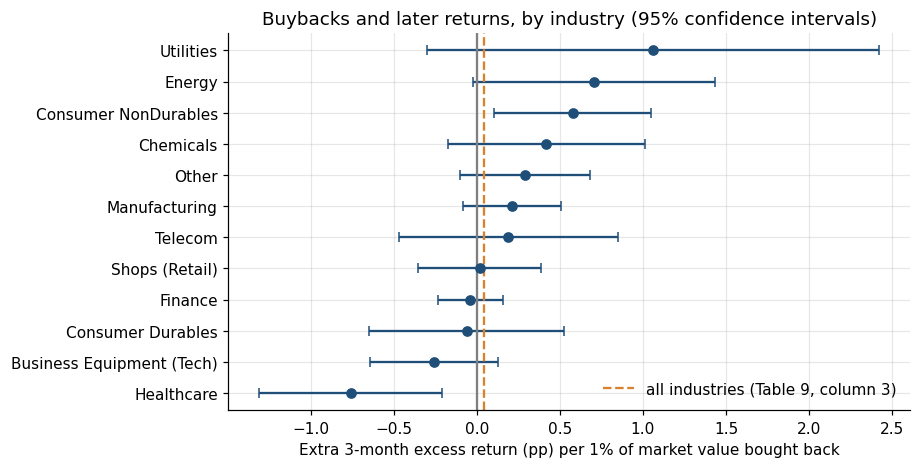

Wald test that all 12 industry slopes are equal: chi2(11) = 31.6, p-value = 0.0009


,coefficient,s.e.,p-value,firm-quarters,% quarters with buyback
industry,,,,,
Healthcare,-0.757,0.281,0.007,26857,27.542
Business Equipment (Tech),-0.255,0.197,0.195,29649,52.454
Consumer Durables,-0.060,0.299,0.840,4273,53.475
Finance,-0.038,0.099,0.702,39033,52.550
Shops (Retail),0.018,0.189,0.922,18009,58.176
Telecom,0.191,0.336,0.569,4049,49.839
Manufacturing,0.214,0.150,0.153,16388,52.551
Other,0.288,0.200,0.149,28345,49.645
Chemicals,0.418,0.302,0.167,3967,55.710


In [29]:
ind_rows = []
for ind_name, d in sample.groupby("industry"):
    r = panel_fit(d, Y, ["bb_size"] + CONTROLS, quarter_fe=True)
    b, se = r.params["bb_size"], r.std_errors["bb_size"]
    ind_rows.append({"industry": ind_name, "coefficient": b, "s.e.": se, "p-value": r.pvalues["bb_size"],
                     "firm-quarters": int(r.nobs), "% quarters with buyback": 100 * d["any_bb"].mean()})
ind_res = pd.DataFrame(ind_rows).set_index("industry").sort_values("coefficient")

fig, ax = plt.subplots(figsize=(8, 4.45))
yy = np.arange(len(ind_res))
ax.errorbar(ind_res["coefficient"], yy, xerr=1.96 * ind_res["s.e."], fmt="o", color=NAVY, capsize=3)
ax.axvline(0, color="grey")
ax.axvline(main_models["(3) + Quarter & industry FE"].params["bb_size"], color=ORANGE, ls="--",
           label="all industries (Table 9, column 3)")
ax.set_yticks(yy, ind_res.index)
ax.set_xlabel("Extra 3-month excess return (pp) per 1% of market value bought back")
ax.set_title("Buybacks and later returns, by industry (95% confidence intervals)")
ax.legend(frameon=False, loc="lower right")
plt.show()

# formal test: one pooled model with a separate buyback slope per industry; H0 = all slopes equal
industries = sorted(sample["industry"].unique())
inter = []
for k, ind_name in enumerate(industries):
    sample[f"bb_x_{k}"] = sample["bb_size"] * (sample["industry"] == ind_name)
    inter.append(f"bb_x_{k}")
res_inter = panel_fit(sample, Y, inter + CONTROLS, quarter_fe=True, industry_fe=True)
wald = res_inter.wald_test(formula=[f"{inter[0]} - {c} = 0" for c in inter[1:]])
print(f"Wald test that all {len(industries)} industry slopes are equal: chi2({len(industries) - 1}) = "
      f"{wald.stat:.1f}, p-value = {wald.pval:.4f}")
ind_res.round(3)

**Report Table 11.** Robustness checks. Each column re-runs Column (3) of Table 9 (Panel A) and Table 10 (Panel B).

In [30]:
big = sample[(sample["mcap_lag"] >= 100) & (sample["mthprc"].abs() >= 5)]
checks = {"(1) Main (3-month)": (sample, Y, None), "(2) 12-month return": (sample, "exret12_pct", None),
          "(3) No small stocks": (big, Y, None), "(4) Value-weighted": (sample, Y, "mcap_lag")}
table4, fits = {}, {}
for name, (d, yv, w) in checks.items():
    a = panel_fit(d, yv, ["bb_size"] + CONTROLS, quarter_fe=True, industry_fe=True, weights=w)
    b = panel_fit(d, yv, GROUPS + CONTROLS, quarter_fe=True, industry_fe=True, weights=w)
    fits[name] = a
    col = {}
    for res, v, lab in [(a, "bb_size", "A. Buyback size (% of mkt value)"), (b, "g_small", "B. Small buyback (0-0.5%)"),
                        (b, "g_medium", "B. Medium buyback (0.5-2%)"), (b, "g_large", "B. Large buyback (>2%)")]:
        col[lab] = f"{res.params[v]:.3f}{stars(res.pvalues[v])}"
        col[lab + " "] = f"({res.std_errors[v]:.3f})"
    col["Observations"] = f"{int(a.nobs):,}"
    table4[name] = col
pd.DataFrame(table4)

,(1) Main (3-month),(2) 12-month return,(3) No small stocks,(4) Value-weighted
A. Buyback size (% of mkt value),0.043,0.249,0.044,-0.066
A. Buyback size (% of mkt value),(0.111),(0.230),(0.095),(0.160)
B. Small buyback (0-0.5%),0.526***,1.790***,0.398**,-0.212
B. Small buyback (0-0.5%),(0.174),(0.493),(0.171),(0.418)
B. Medium buyback (0.5-2%),0.627*,1.850***,0.549*,-0.020
B. Medium buyback (0.5-2%),(0.337),(0.709),(0.294),(0.297)
B. Large buyback (>2%),0.284,1.275,0.207,-0.251
B. Large buyback (>2%),(0.420),(0.861),(0.356),(0.603)
Observations,"191,972","183,214","142,805","191,972"


**Section 6.2.4 (not tabulated in the report).** The correlation of a firm's regression residual with its own residual 1 to 4 quarters earlier, for the 3-month and 12-month returns.

In [31]:
def residual_autocorr(res, lags=(1, 2, 3, 4)):
    e = res.resids.rename("e").reset_index().sort_values(["entity", "qidx"])
    out = {}
    for k in lags:
        prev = e.groupby("entity")[["qidx", "e"]].shift(k)
        ok = (e["qidx"] - prev["qidx"]) == k
        out[f"{k} quarter(s) apart"] = np.corrcoef(e.loc[ok, "e"], prev.loc[ok, "e"])[0, 1]
    return pd.Series(out)


pd.DataFrame({"3-month return (main)": residual_autocorr(fits["(1) Main (3-month)"]),
              "12-month return": residual_autocorr(fits["(2) 12-month return"])}).T.round(2)

,1 quarter(s) apart,2 quarter(s) apart,3 quarter(s) apart,4 quarter(s) apart
3-month return (main),0.080,0.010,0.010,-0.010
12-month return,0.720,0.470,0.230,0.000


## 7. The WRDS queries in full
The exact SQL run by the download in Section 1.

In [32]:
for name, (sql, date_cols, by_year) in WRDS_QUERIES.items():
    print(f"-- {name}.parquet" + (" (downloaded one year at a time)" if by_year else ""))
    shown = sql.replace("%(start)s", f"'{START_YEAR}-01-01'").replace("%(end)s", f"'{END_YEAR}-12-31'")
    print(textwrap.dedent(shown).strip() + ";\n")

-- comp_fundq.parquet (downloaded one year at a time)
SELECT f.gvkey, f.datadate, f.fyearq, f.fqtr, f.tic, f.conm, f.rdq,
       f.prstkcy, f.dvy, f.stkcoy, f.oancfy,
       f.cshoq, f.prccq, f.atq, f.ltq, f.ceqq, f.niq, f.saleq, f.cheq, f.dlttq, f.dlcq, c.sic
FROM comp.fundq AS f JOIN comp.company AS c ON f.gvkey = c.gvkey
WHERE f.indfmt = 'INDL' AND f.datafmt = 'STD' AND f.popsrc = 'D' AND f.consol = 'C'
  AND f.fic = 'USA' AND f.datadate BETWEEN '2008-01-01' AND '2025-12-31';

-- comp_filedates.parquet
SELECT gvkey, datadate, srctype, filedate FROM comp.co_filedate
WHERE srctype IN ('10Q', '10K') AND popsrc = 'D' AND consol = 'C'
  AND datadate BETWEEN '2008-01-01' AND '2025-12-31';

-- crsp_msf.parquet (downloaded one year at a time)
SELECT permno, mthcaldt, mthret, mthprc, mthcap, siccd, primaryexch,
       sharetype, securitytype, securitysubtype, usincflg, issuertype
FROM crsp.msf_v2 WHERE mthcaldt BETWEEN '2008-01-01' AND '2025-12-31';

-- ccm_link.parquet
SELECT gvkey, lpermno